# 04 — EfficientNet-B0 comparison (NeuroVision, Phase 4 / experiment E3)
Same data, augmentation, loss, optimizer and two-stage recipe as ResNet18 (notebook 03), so the comparison is fair.
GPU runtime required. Validation only; the test set stays untouched.

In [2]:
KAGGLE_DATASET = "sainibharat10/neurovision-brain-mri"
import os, glob, shutil, zipfile
DATA, ART = "/content/data", "/content/artifacts"
os.makedirs(ART, exist_ok=True)
!pip -q install kagglehub
import kagglehub

def find_root(p):
    hits = glob.glob(f"{p}/**/train", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

if not os.path.isdir(f"{DATA}/train"):
    try:
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception:
        kagglehub.login()
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    root = find_root(path)
    if root is None:
        for z in glob.glob(f"{path}/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        for z in glob.glob("/content/_raw/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        root = find_root("/content/_raw")
    assert root, "train/ folder not found"
    shutil.copytree(root, DATA, dirs_exist_ok=True)
print(sorted(os.listdir(DATA)))

100%|██████████| 107M/107M [00:01<00:00, 61.9MB/s] 

Extracting files...


['test', 'train', 'val']


In [3]:
import json, time, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from sklearn.metrics import classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)

SPLITS = ["train", "val", "test"]
CLASSES = sorted(os.listdir(f"{DATA}/train"))
rows = [(s, c, f"{DATA}/{s}/{c}/{f}") for s in SPLITS for c in CLASSES for f in os.listdir(f"{DATA}/{s}/{c}")]
df = pd.DataFrame(rows, columns=["split", "cls", "path"])   # near-duplicate check: false alarm, keep all images

device: cuda


## Data: decode + resize once, keep in RAM (fast epochs)

In [4]:
IMG = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]     # ImageNet stats (required for pretrained weights)

def load(p): return np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG), Image.BILINEAR))
def make_cache(frame):
    with ThreadPoolExecutor(8) as ex: xs = list(ex.map(load, frame.path))
    return torch.from_numpy(np.stack(xs)).permute(0, 3, 1, 2).contiguous(), [CLASSES.index(c) for c in frame.cls]

aug = T.Compose([T.RandomRotation(10), T.RandomAffine(0, translate=(0.05, 0.05)), T.ColorJitter(0.1, 0.1)])
norm = T.Normalize(MEAN, STD)

class CachedDS(Dataset):
    def __init__(self, X, y, train): self.X, self.y, self.train = X, y, train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.X[i]
        if self.train: x = aug(x)
        return norm(x.float() / 255), self.y[i]

cache = {s: make_cache(df[df.split == s]) for s in SPLITS}
ds = {s: CachedDS(*cache[s], train=(s == "train")) for s in SPLITS}
dl = {s: DataLoader(ds[s], batch_size=32, shuffle=(s == "train"), num_workers=2,
                    persistent_workers=True, pin_memory=True) for s in SPLITS}
n = np.bincount(ds["train"].y, minlength=len(CLASSES))
class_weights = torch.tensor(n.sum() / (len(CLASSES) * n), dtype=torch.float32).to(device)
print({s: len(ds[s]) for s in SPLITS})

{'train': 4160, 'val': 892, 'test': 889}


## Model: ImageNet-pretrained EfficientNet-B0 with a new 4-class head

In [5]:
def build_effnet_b0(n_classes=4):
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)   # keeps the built-in Dropout(0.2)
    return m

model = build_effnet_b0(len(CLASSES)).to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")      # Grad-CAM target later: model.features[-1]

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s]


4,012,672 parameters


## Training utilities (best checkpoint by validation macro-F1)

In [6]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval(); loss_sum, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            out = model(x); loss = criterion(out, y)
        loss_sum += loss.item() * len(y); ys += y.tolist(); ps += out.argmax(1).tolist()
    return loss_sum / len(ys), f1_score(ys, ps, average="macro"), np.mean(np.array(ys) == np.array(ps)), ys, ps

def fit(model, name, params, lr, epochs, patience, weight_decay=1e-4, freeze_bn=False):
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    scaler = torch.amp.GradScaler(enabled=(device == "cuda"))
    hist, best, bad = [], -1, 0
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); tl, tc, tn = 0.0, 0, 0
        if freeze_bn:                                   # keep BatchNorm statistics fixed while backbone is frozen
            for m in model.modules():
                if isinstance(m, nn.BatchNorm2d): m.eval()
        for x, y in dl["train"]:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
                out = model(x); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        vl, vf1, vacc, _, _ = evaluate(model, dl["val"], criterion)
        sched.step(vf1)
        hist.append(dict(epoch=ep, train_loss=tl / tn, train_acc=tc / tn, val_loss=vl, val_acc=vacc,
                         val_macro_f1=vf1, lr=opt.param_groups[0]["lr"]))
        flag = ""
        if vf1 > best:
            best, bad, flag = vf1, 0, " *saved*"
            torch.save({"model": model.state_dict(), "classes": CLASSES, "val_macro_f1": vf1, "epoch": ep},
                       f"{ART}/{name}_best.pth")
        else:
            bad += 1
        print(f"ep {ep:02d} | train loss {tl/tn:.4f} acc {tc/tn:.3f} | val loss {vl:.4f} acc {vacc:.3f} "
              f"F1 {vf1:.3f} | {time.time()-t0:.0f}s{flag}")
        if bad >= patience: print("early stopping"); break
    json.dump(hist, open(f"{ART}/{name}_history.json", "w"))
    return pd.DataFrame(hist)

## Stage 1 — train the new head only (backbone frozen)

In [7]:
for p in model.parameters(): p.requires_grad = False
for p in model.classifier.parameters(): p.requires_grad = True
h1 = fit(model, "effnet_b0_stage1", params=model.classifier.parameters(), lr=1e-3, epochs=5, patience=5, freeze_bn=True)

ep 01 | train loss 0.7651 acc 0.706 | val loss 0.5610 acc 0.794 F1 0.796 | 36s *saved*
ep 02 | train loss 0.5336 acc 0.801 | val loss 0.5018 acc 0.840 F1 0.842 | 31s *saved*
ep 03 | train loss 0.4669 acc 0.824 | val loss 0.4504 acc 0.855 F1 0.863 | 31s *saved*
ep 04 | train loss 0.4337 acc 0.838 | val loss 0.4298 acc 0.851 F1 0.863 | 39s *saved*
ep 05 | train loss 0.4145 acc 0.842 | val loss 0.4110 acc 0.848 F1 0.855 | 30s


## Stage 2 — fine-tune the whole network at a lower learning rate

In [8]:
model.load_state_dict(torch.load(f"{ART}/effnet_b0_stage1_best.pth", map_location=device)["model"])
for p in model.parameters(): p.requires_grad = True
h2 = fit(model, "effnet_b0", params=model.parameters(), lr=1e-4, epochs=25, patience=6)

ep 01 | train loss 0.4815 acc 0.811 | val loss 0.3266 acc 0.890 F1 0.891 | 44s *saved*
ep 02 | train loss 0.2240 acc 0.918 | val loss 0.1823 acc 0.933 F1 0.932 | 34s *saved*
ep 03 | train loss 0.1460 acc 0.941 | val loss 0.2108 acc 0.945 F1 0.942 | 35s *saved*
ep 04 | train loss 0.1093 acc 0.957 | val loss 0.1256 acc 0.954 F1 0.954 | 33s *saved*
ep 05 | train loss 0.0659 acc 0.976 | val loss 0.1057 acc 0.966 F1 0.967 | 35s *saved*
ep 06 | train loss 0.0576 acc 0.979 | val loss 0.0988 acc 0.965 F1 0.966 | 33s
ep 07 | train loss 0.0509 acc 0.981 | val loss 0.1007 acc 0.964 F1 0.965 | 33s
ep 08 | train loss 0.0400 acc 0.986 | val loss 0.0786 acc 0.973 F1 0.972 | 35s *saved*
ep 09 | train loss 0.0433 acc 0.985 | val loss 0.0774 acc 0.979 F1 0.978 | 34s *saved*
ep 10 | train loss 0.0326 acc 0.988 | val loss 0.0781 acc 0.973 F1 0.973 | 35s
ep 11 | train loss 0.0293 acc 0.988 | val loss 0.0976 acc 0.966 F1 0.966 | 33s
ep 12 | train loss 0.0233 acc 0.991 | val loss 0.0680 acc 0.979 F1 0.978 | 

## Curves (stage 2)

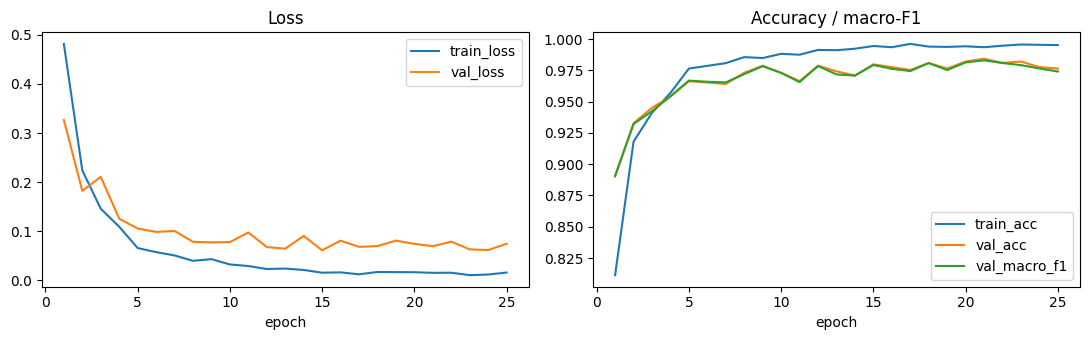

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
h2.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="Loss")
h2.plot(x="epoch", y=["train_acc", "val_acc", "val_macro_f1"], ax=ax[1], title="Accuracy / macro-F1")
plt.tight_layout(); plt.show()

## Validation report with the best checkpoint (test set still untouched)

best epoch: 21
EfficientNet-B0  VAL accuracy 0.9843 | macro-F1 0.9830
ResNet18         VAL accuracy 0.9664 | macro-F1 0.9657   (notebook 03)
Baseline CNN     VAL accuracy 0.9204 | macro-F1 0.9222   (notebook 02)

              precision    recall  f1-score   support

      glioma      0.982     0.997     0.989       329
  meningioma      0.991     0.968     0.979       222
    no_tumor      0.991     0.966     0.979       118
   pituitary      0.978     0.991     0.984       223

    accuracy                          0.984       892
   macro avg      0.985     0.981     0.983       892
weighted avg      0.984     0.984     0.984       892



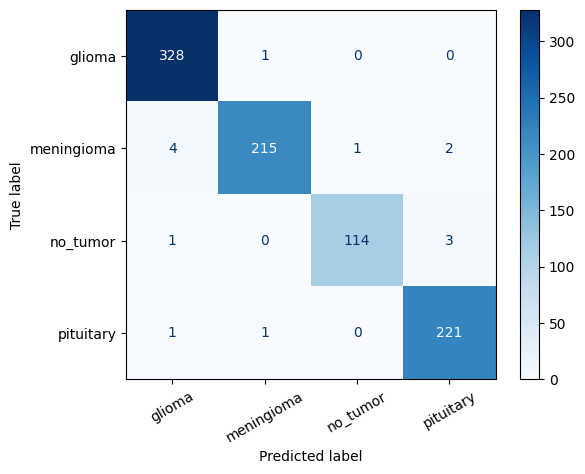

In [10]:
ck = torch.load(f"{ART}/effnet_b0_best.pth", map_location=device)
model.load_state_dict(ck["model"]); print("best epoch:", ck["epoch"])
_, f1, acc, ys, ps = evaluate(model, dl["val"], nn.CrossEntropyLoss(weight=class_weights))
print(f"EfficientNet-B0  VAL accuracy {acc:.4f} | macro-F1 {f1:.4f}")
print("ResNet18         VAL accuracy 0.9664 | macro-F1 0.9657   (notebook 03)")
print("Baseline CNN     VAL accuracy 0.9204 | macro-F1 0.9222   (notebook 02)\n")
print(classification_report(ys, ps, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(ys, ps), display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=30)
plt.show()

## Comparison table: accuracy, size, speed
Speed is single-image GPU inference (ms, averaged over 100 runs). Weights are irrelevant for timing.

In [11]:
from sklearn.metrics import recall_score
def bench(m, n=100):
    m = m.to(device).eval(); x = torch.randn(1, 3, 224, 224, device=device)
    sync = torch.cuda.synchronize if device == "cuda" else (lambda: None)
    with torch.no_grad():
        for _ in range(10): m(x)
        sync(); t = time.time()
        for _ in range(n): m(x)
        sync()
    return (time.time() - t) / n * 1000

res = models.resnet18(weights=None); res.fc = nn.Linear(512, 4)
npar = lambda m: sum(p.numel() for p in m.parameters())
men = CLASSES.index("meningioma")
cmp = pd.DataFrame([
    dict(model="ResNet18",        params_M=npar(res) / 1e6,   size_MB=npar(res) * 4 / 1e6,   ms_per_img=bench(res),
         val_acc=0.9664, val_macro_f1=0.9657, meningioma_recall=0.941, best_epoch=3),
    dict(model="EfficientNet-B0", params_M=npar(model) / 1e6, size_MB=npar(model) * 4 / 1e6, ms_per_img=bench(model),
         val_acc=acc, val_macro_f1=f1, meningioma_recall=recall_score(ys, ps, average=None)[men], best_epoch=ck["epoch"]),
]).round(4)
display(cmp)

,model,params_M,size_MB,ms_per_img,val_acc,val_macro_f1,meningioma_recall,best_epoch
0,ResNet18,11.1786,44.7143,3.4103,0.9664,0.9657,0.9410,3
1,EfficientNet-B0,4.0127,16.0507,10.5330,0.9843,0.9830,0.9685,21


## Look at the mistakes (validation)

14 misclassified of 892


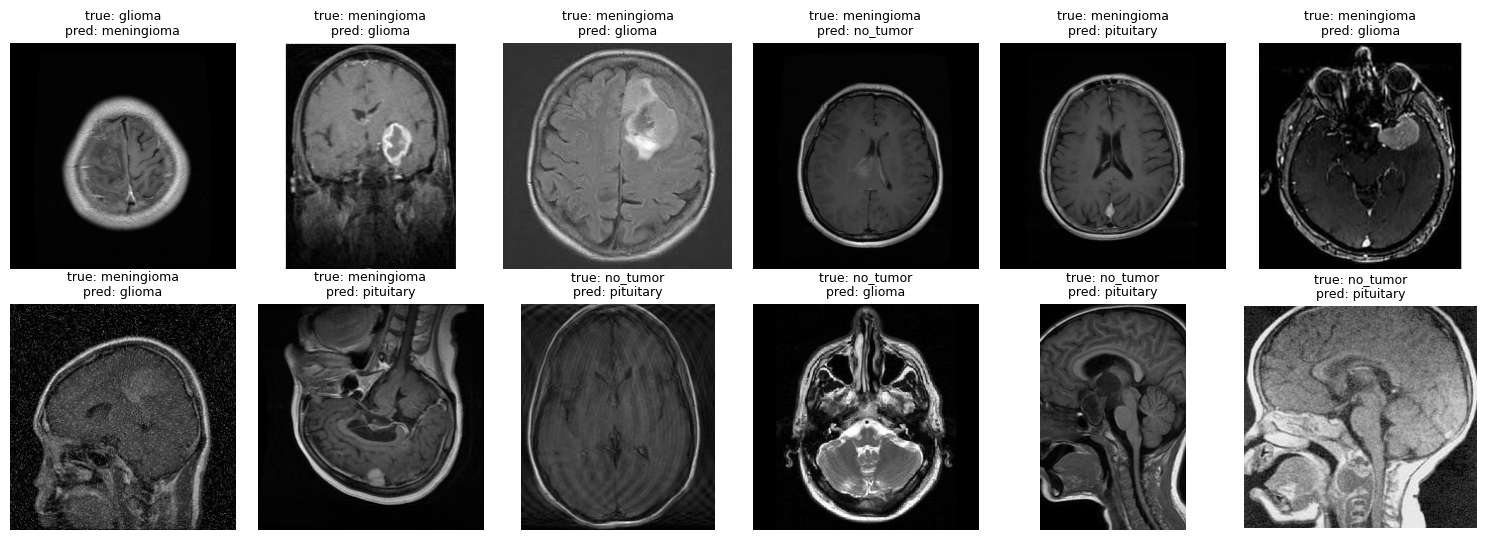

In [12]:
val_paths = df[df.split == "val"].path.tolist()     # same order as the cached val set
wrong = [i for i, (a, b) in enumerate(zip(ys, ps)) if a != b]
print(len(wrong), "misclassified of", len(ys))
fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
for a, i in zip(ax.ravel(), wrong[:12]):
    a.imshow(Image.open(val_paths[i]).convert("RGB")); a.axis("off")
    a.set_title(f"true: {CLASSES[ys[i]]}\npred: {CLASSES[ps[i]]}", fontsize=9)
plt.tight_layout(); plt.show()

## Save and download artifacts

In [ ]:
# json.dump(CLASSES, open(f"{ART}/class_names.json", "w"))
# from google.colab import files
# shutil.make_archive("/content/neurovision_effnet_b0", "zip", ART)
# files.download("/content/neurovision_effnet_b0.zip")

## Notes to fill in
- EfficientNet-B0 vs ResNet18 (val accuracy, macro-F1, meningioma recall):
- Size and speed trade-off:
- Final model choice (validation + practical considerations) and why: